<center><h1>Meyyappan_Shammu_HW7</h1></center>

Name: Shammu Meyyappan
<br>
Github Username: ShammuMeyyappan
<br>
USC ID: 4085790637

## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

Import packages

In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC, LinearSVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import squareform
import warnings
warnings.filterwarnings("ignore")
RANDOM_STATE = 53

### (a) Download the Anuran Calls (MFCCs) Data Set

In [32]:
df = pd.read_csv("../data/Frogs_MFCCs.csv")

feature_cols = [c for c in df.columns if c.startswith("MFCCs")]
label_cols = ["Family", "Genus", "Species"]
X = df[feature_cols]
Y = df[label_cols]

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, train_size=0.70, random_state=RANDOM_STATE, stratify=Y["Species"]
)

### (b) Train a classifier for each label

#### (i) Research

Exact match ratio is the fraction of rows where all 3 labels are correct. Hamming loss is the fraction of individual labels that are wrong averaged over all rows and all 3 labels, where lower is better. And lastly, Hamming score is the fraction of individual labels that are right, where higher is better.

[Source: Sorower, M. S. (2010), A Literature Survey on Algorithms for Multi-label Learning, Oregon State University]

In [33]:
def multilabel_metrics(Y_true, Y_pred):
    """Helper function; Y_true and Y_pred are tables with one column per label."""
    Y_true = np.asarray(Y_true)
    Y_pred = np.asarray(Y_pred)
    wrong = (Y_true != Y_pred)
    exact_match = np.mean(~wrong.any(axis=1))
    hamming_loss = wrong.mean()
    return {"exact_match": exact_match,
            "hamming_loss": hamming_loss,
            "hamming_score": 1 - hamming_loss}

#### (ii) Train a SVM for each of the labels

In [34]:
def sigma_to_gamma(sigma):
    return 1 / (2 * sigma**2)

C_grid = [1e-1, 1e0, 1e1, 1e2, 1e3, 1e4]
sigma_grid = [0.25, 0.5, 0.75, 1.0, 1.5, 2.0]
gamma_grid = [sigma_to_gamma(s) for s in sigma_grid]

cv10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)

def fit_per_label(make_model, param_grid, X_tr, Y_tr, X_te, Y_te):
    """Grid-searches one model per label, predicts test set, returns summary table and test predictions."""
    rows = []
    Y_pred = pd.DataFrame(index=Y_te.index)
    for label in label_cols:
        search = GridSearchCV(make_model(), param_grid, cv=cv10, scoring="accuracy", n_jobs=-1)
        search.fit(X_tr, Y_tr[label])
        Y_pred[label] = search.predict(X_te)
        rows.append({
            "label": label,
            "best_params": search.best_params_,
            "cv_accuracy": round(search.best_score_, 4),
            "test_accuracy": round(accuracy_score(Y_te[label], Y_pred[label]), 4),
            "test_balanced_acc": round(balanced_accuracy_score(Y_te[label], Y_pred[label]), 4),
        })
    return pd.DataFrame(rows), Y_pred

In [35]:
# Raw attributes

def rbf_raw():
    return OneVsRestClassifier(SVC(kernel="rbf"))

grid_raw = {"estimator__C": C_grid, "estimator__gamma": gamma_grid}

table_rbf_raw, pred_rbf_raw = fit_per_label(rbf_raw, grid_raw, X_train, Y_train, X_test, Y_test)
table_rbf_raw

,label,best_params,cv_accuracy,test_accuracy,test_balanced_acc
0,Family,"{'estimator__C': 10.0, 'estimator__gamma': 2.0}",0.9929,0.9949,0.9838
1,Genus,"{'estimator__C': 10.0, 'estimator__gamma': 2.0}",0.9907,0.9921,0.9678
2,Species,"{'estimator__C': 10.0, 'estimator__gamma': 2.0}",0.9895,0.9921,0.9732


In [36]:
# For comparison later

results = {} 
results["Gaussian SVM (raw)"] = multilabel_metrics(Y_test, pred_rbf_raw)

In [37]:
# Standardized attributes

def rbf_std():
    return Pipeline([
        ("scale", StandardScaler()),
        ("svm", OneVsRestClassifier(SVC(kernel="rbf"))),
    ])

sigma_grid_std = [1, 2, 3, 4, 5, 6]
grid_std = {"svm__estimator__C": C_grid,
            "svm__estimator__gamma": [sigma_to_gamma(s) for s in sigma_grid_std]}

table_rbf_std, pred_rbf_std = fit_per_label(rbf_std, grid_std, X_train, Y_train, X_test, Y_test)
table_rbf_std

,label,best_params,cv_accuracy,test_accuracy,test_balanced_acc
0,Family,"{'svm__estimator__C': 10.0, 'svm__estimator__g...",0.9911,0.9931,0.9831
1,Genus,"{'svm__estimator__C': 10.0, 'svm__estimator__g...",0.9907,0.9907,0.9687
2,Species,"{'svm__estimator__C': 100.0, 'svm__estimator__...",0.9891,0.9903,0.9718


In [38]:
results["Gaussian SVM (standardized)"] = multilabel_metrics(Y_test, pred_rbf_std)

#### (iii) Repeat 1(b)ii with L1-penalized SVMs

In [39]:
def l1_svm():
    return Pipeline([
        ("scale", StandardScaler()),
        ("svm", LinearSVC(penalty="l1", dual=False, max_iter=10000)),
    ])

grid_l1 = {"svm__C": [1e-3, 1e-2, 1e-1, 1e0, 1e1]}

table_l1, pred_l1 = fit_per_label(l1_svm, grid_l1, X_train, Y_train, X_test, Y_test)
table_l1

,label,best_params,cv_accuracy,test_accuracy,test_balanced_acc
0,Family,{'svm__C': 10.0},0.9357,0.9361,0.6904
1,Genus,{'svm__C': 10.0},0.9484,0.9518,0.8058
2,Species,{'svm__C': 10.0},0.9555,0.9611,0.8985


In [40]:
results["L1 linear SVM"] = multilabel_metrics(Y_test, pred_l1)

#### (iv) Repeat 1(b)iii by using SMOTE or any other method for imbalance

In [41]:
def l1_svm_smote():
    return ImbPipeline([
        ("scale", StandardScaler()),
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("svm", LinearSVC(penalty="l1", dual=False, max_iter=10000)),
    ])

table_l1_smote, pred_l1_smote = fit_per_label(l1_svm_smote, grid_l1, X_train, Y_train, X_test, Y_test)
table_l1_smote

,label,best_params,cv_accuracy,test_accuracy,test_balanced_acc
0,Family,{'svm__C': 10.0},0.9196,0.9208,0.9197
1,Genus,{'svm__C': 10.0},0.9136,0.9078,0.9091
2,Species,{'svm__C': 1.0},0.9543,0.9537,0.9233


In [42]:
results["L1 linear SVM + SMOTE"] = multilabel_metrics(Y_test, pred_l1_smote)
pd.DataFrame(results).T.round(4)

,exact_match,hamming_loss,hamming_score
Gaussian SVM (raw),0.9898,0.0069,0.9931
Gaussian SVM (standardized),0.9870,0.0086,0.9914
L1 linear SVM,0.9171,0.0503,0.9497
L1 linear SVM + SMOTE,0.8587,0.0726,0.9274


Based on these results, the Gaussian-kernel SVM appears to be the best model, standardization provides no benefit to using the raw attributes, and SMOTE appears to hurt overall accuracy.

## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

### (a) Use k-means clustering

In [43]:
X_all = df[feature_cols].values
Y_all = df[label_cols].values
k_values = range(2, 51)

### (b) Determine which family is the majority

In [44]:
def majority_triplets(cluster_ids, Y):
    """Returns a table of the most common Family/Genus/Species."""
    tmp = pd.DataFrame(Y, columns=label_cols)
    tmp["cluster"] = cluster_ids
    return tmp.groupby("cluster")[label_cols].agg(lambda s: s.value_counts().idxmax())

### (c) Calculate the average Hamming distance, Hamming score, and Hamming loss

In [45]:
def hamming_results(cluster_ids, Y, majority):
    Y_pred = majority.loc[cluster_ids, label_cols].values
    wrong = (Y != Y_pred)
    distance = wrong.sum(axis=1).mean()
    loss = wrong.mean()
    return {"hamming_distance": distance, "hamming_loss": loss, "hamming_score": 1 - loss}

In [46]:
N_RUNS = 50
mc_rows = []

for run in range(N_RUNS):
    scores = []
    for k in k_values:
        km = KMeans(n_clusters=k, n_init=3, random_state=run).fit(X_all)
        scores.append(silhouette_score(X_all, km.labels_, sample_size=2000, random_state=run))
    k_run = list(k_values)[int(np.argmax(scores))]

    km = KMeans(n_clusters=k_run, n_init=3, random_state=run).fit(X_all)
    maj = majority_triplets(km.labels_, Y_all)

    res = hamming_results(km.labels_, Y_all, maj)
    res["run"] = run
    res["k"] = k_run
    mc_rows.append(res)

mc = pd.DataFrame(mc_rows)

In [47]:
mc[["hamming_distance", "hamming_loss", "hamming_score"]].agg(["mean", "std"]).round(4)

,hamming_distance,hamming_loss,hamming_score
mean,0.6778,0.2259,0.7741
std,0.0705,0.0235,0.0235


## 3. ISLR 12.6.2

### (a) and (b) Complete and Single Linkage Dendrograms

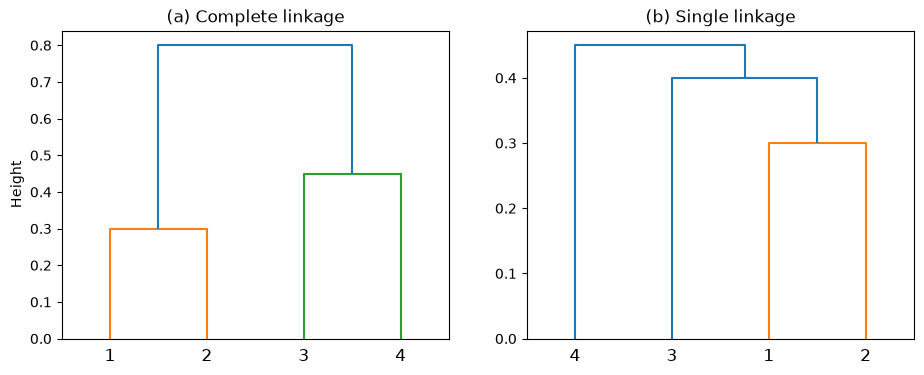

In [48]:
D = np.array([[0.0, 0.3, 0.4, 0.7],
              [0.3, 0.0, 0.5, 0.8],
              [0.4, 0.5, 0.0, 0.45],
              [0.7, 0.8, 0.45, 0.0]])
condensed = squareform(D)
obs_labels = ["1", "2", "3", "4"]

Z_complete = linkage(condensed, method="complete")
Z_single = linkage(condensed, method="single")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
dendrogram(Z_complete, labels=obs_labels, ax=axes[0])
axes[0].set_title("(a) Complete linkage"); axes[0].set_ylabel("Height")
dendrogram(Z_single, labels=obs_labels, ax=axes[1])
axes[1].set_title("(b) Single linkage")
plt.show()

### (c) and (d) Dendrogram cutting

In [49]:
clusters_c = fcluster(Z_complete, t=2, criterion="maxclust")
print("Complete linkage:", clusters_c)

clusters_d = fcluster(Z_single, t=2, criterion="maxclust")
print("Single linkage:  ", clusters_d)

Complete linkage: [1 1 2 2]
Single linkage:   [1 1 1 2]


### (e) Rearranged dendrogram

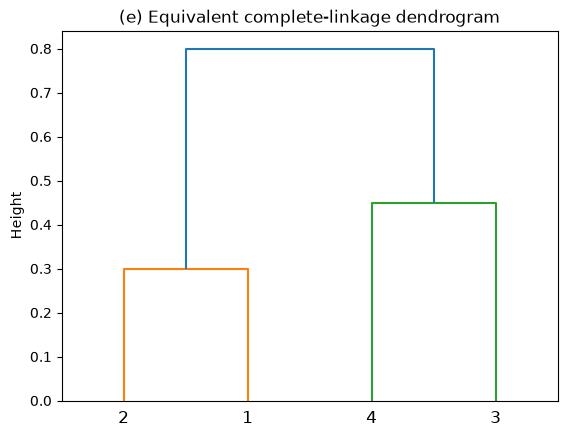

In [50]:
order = [3, 2, 1, 0]
D_reordered = D[order][:, order]
labels_reordered = [obs_labels[i] for i in order]
Z_complete_e = linkage(squareform(D_reordered), method="complete")

dendrogram(Z_complete_e, labels=labels_reordered)
plt.title("(e) Equivalent complete-linkage dendrogram")
plt.ylabel("Height")
plt.show()